<a href="https://colab.research.google.com/github/carollinemelloo/ProcessamentoDeImagens/blob/main/Portfolio02bi2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [2]:
def implot_comparacao(img_orig, img_semantica, img_instancia, titulo_base=""):
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img_orig, cmap='gray' if len(img_orig.shape) == 2 else None)
    plt.title(f'{titulo_base} - Original')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(img_semantica, cmap='gray')
    plt.title(f'{titulo_base} - Seg. Semântica')
    plt.axis('off')

    plt.subplot(1, 3, 3)

    instancia_vis = np.ma.masked_where(img_instancia <= 1, img_instancia)
    plt.imshow(img_orig, cmap='gray' if len(img_orig.shape) == 2 else None)
    plt.imshow(instancia_vis, cmap='tab20', alpha=0.7)
    plt.title(f'{titulo_base} - Seg. por Instância')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [3]:
def processar_segmentacao(img):
    if len(img.shape) == 3:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    else:
        gray = img.copy()

    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, semantica = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    kernel = np.ones((3, 3), np.uint8)
    opening = cv2.morphologyEx(semantica, cv2.MORPH_OPEN, kernel, iterations=2)

    sure_bg = cv2.dilate(opening, kernel, iterations=3)

    dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
    _, sure_fg = cv2.threshold(dist_transform, 0.35 * dist_transform.max(), 255, 0)
    sure_fg = np.uint8(sure_fg)

    unknown = cv2.subtract(sure_bg, sure_fg)

    _, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0

    img_color = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    instancia = cv2.watershed(img_color, markers)

    return semantica, instancia

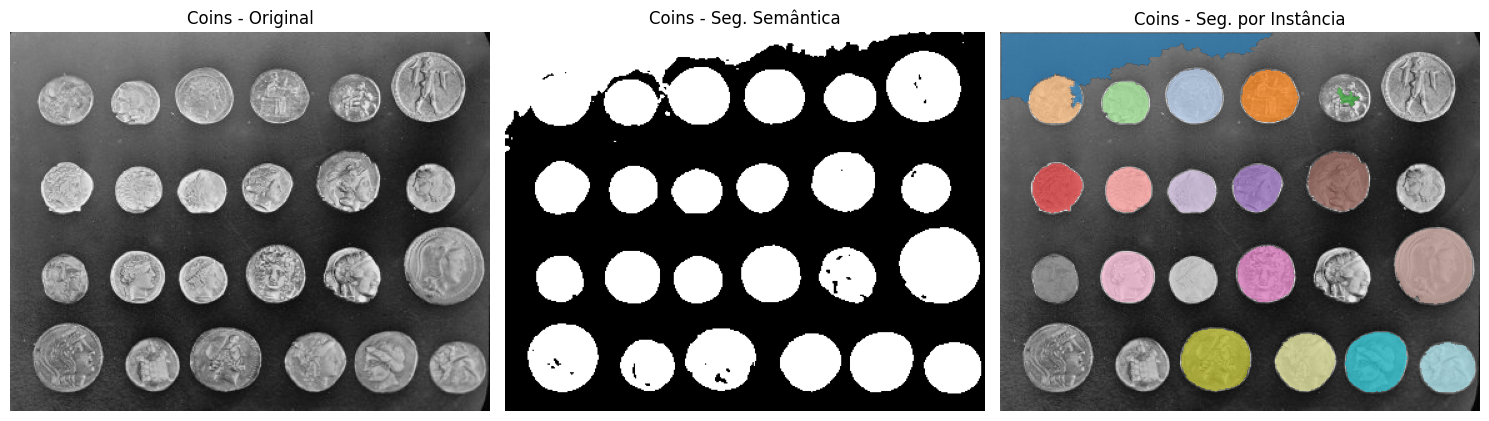

In [4]:
img1 = data.coins()
semantica1, instancia1 = processar_segmentacao(img1)
implot_comparacao(img1, semantica1, instancia1, titulo_base="Coins")

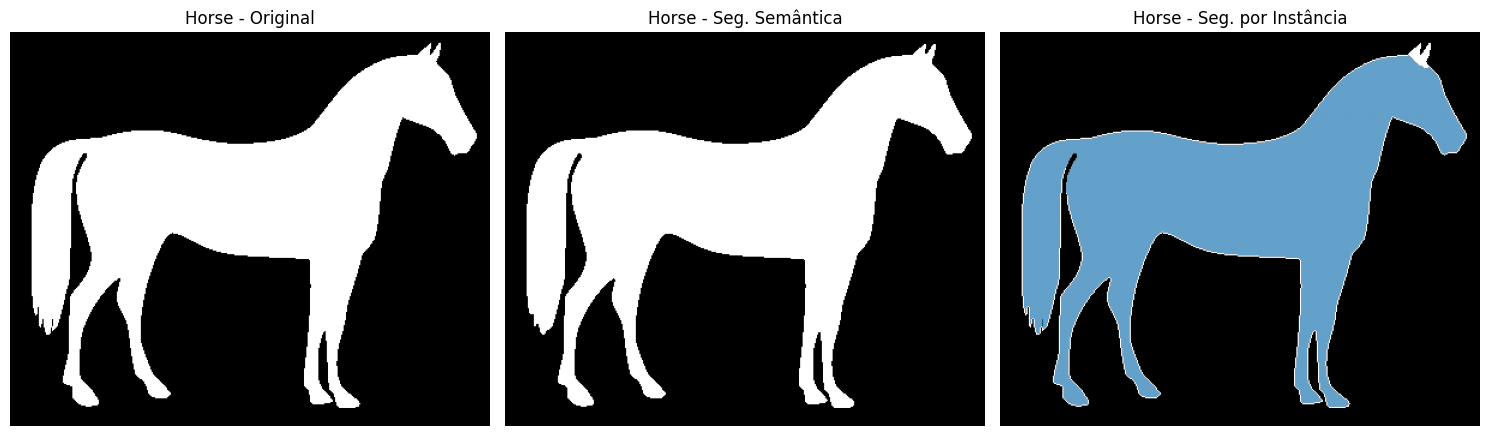

In [5]:
img2 = data.horse()
img2 = cv2.bitwise_not(img2.astype(np.uint8) * 255)
semantica2, instancia2 = processar_segmentacao(img2)
implot_comparacao(img2, semantica2, instancia2, titulo_base="Horse")

# Analise

Imagem 1 (coins): Houve diferença significativa. A segmentação semântica apenas separou as moedas do fundo, aglutinando objetos próximos em um único bloco. A segmentação por instância separou e identificou cada moeda individualmente.

Imagem 2 (horse): Não houve diferença prática. Por existir apenas um objeto isolado, a segmentação semântica (objeto vs. fundo) e a por instância (identificação da única figura) geraram o mesmo resultado visual.
